In [119]:
import pandas as pd

In [120]:
orders = pd.read_csv("../data/olist_orders_dataset.csv")

In [121]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [122]:
orders.shape

(99441, 8)

In [123]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [124]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [125]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [126]:
orders["order_id"].duplicated().sum()

np.int64(0)

In [127]:
orders["order_purchase_timestamp"].head()

0    2017-10-02 10:56:33
1    2018-07-24 20:41:37
2    2018-08-08 08:38:49
3    2017-11-18 19:28:06
4    2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: str

In [128]:
orders["order_purchase_timestamp"].dtype

<StringDtype(storage='python', na_value=nan)>

In [129]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

In [130]:
orders["order_purchase_timestamp"].dtype

dtype('<M8[us]')

In [131]:
date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [132]:
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [133]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [134]:
orders[orders["order_status"] != "delivered"]["order_delivered_customer_date"].notnull().value_counts()

order_delivered_customer_date
False    2957
True        6
Name: count, dtype: int64

In [135]:
orders[
    (orders["order_status"] != "delivered") &
    (orders["order_delivered_customer_date"].notnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08


In [136]:
pd.crosstab(
    orders["order_status"],
    orders["order_delivered_customer_date"].notna()
)

order_delivered_customer_date,False,True
order_status,,
approved,2,0
canceled,619,6
created,5,0
delivered,8,96470
invoiced,314,0
processing,301,0
shipped,1107,0
unavailable,609,0


In [137]:
orders_clean = orders.copy()

In [138]:
orders_clean.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [139]:
orders_clean["order_month"] = orders_clean["order_purchase_timestamp"].dt.to_period("M")

In [140]:
orders_clean[["order_purchase_timestamp", "order_month"]].head()

,order_purchase_timestamp,order_month
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02


In [141]:
order_items = pd.read_csv("../data/olist_order_items_dataset.csv")

In [142]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [143]:
order_items.shape

(112650, 7)

In [144]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [145]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [146]:
order_items.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [147]:
order_items_clean = order_items.copy()

In [148]:
order_items_clean["shipping_limit_date"] = pd.to_datetime(
    order_items_clean["shipping_limit_date"]
)

In [149]:
order_items_clean["shipping_limit_date"].dtype

dtype('<M8[us]')

In [150]:
sales = pd.merge(
    orders_clean,
    order_items_clean,
    on="order_id",
    how="inner"
)

In [151]:
sales.shape

(112650, 15)

In [152]:
sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_month,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [153]:
sales["item_revenue"] = sales["price"]

In [154]:
sales[["product_id", "price", "item_revenue"]].head()

,product_id,price,item_revenue
0,87285b34884572647811a353c7ac498a,29.99,29.99
1,595fac2a385ac33a80bd5114aec74eb8,118.70,118.70
2,aa4383b373c6aca5d8797843e5594415,159.90,159.90
3,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,45.00
4,65266b2da20d04dbe00c5c2d3bb7859e,19.90,19.90


In [155]:
sales.groupby("order_status")["item_revenue"].agg(
    ["count", "sum"]
).sort_values("sum", ascending=False)

,count,sum
order_status,,
delivered,110197,13221498.11
shipped,1185,150727.44
canceled,542,95235.27
invoiced,359,61526.37
processing,357,60439.22
unavailable,7,2007.69
approved,3,209.60


In [156]:
delivered_revenue = sales[
    sales["order_status"] == "delivered"
]["item_revenue"].sum()

delivered_revenue

np.float64(13221498.110000001)

In [157]:
sales[["order_purchase_timestamp", "order_month", "order_status", "item_revenue"]].head()

,order_purchase_timestamp,order_month,order_status,item_revenue
0,2017-10-02 10:56:33,2017-10,delivered,29.99
1,2018-07-24 20:41:37,2018-07,delivered,118.70
2,2018-08-08 08:38:49,2018-08,delivered,159.90
3,2017-11-18 19:28:06,2017-11,delivered,45.00
4,2018-02-13 21:18:39,2018-02,delivered,19.90


In [158]:
monthly_revenue = (
    sales[sales["order_status"] == "delivered"]
    .groupby("order_month")["item_revenue"]
    .sum()
    .reset_index()
)

In [159]:
monthly_revenue.head(10)

,order_month,item_revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


In [160]:
monthly_revenue.tail()

,order_month,item_revenue
18,2018-04,973534.09
19,2018-05,977544.69
20,2018-06,856077.86
21,2018-07,867953.46
22,2018-08,838576.64


In [161]:
monthly_revenue.shape

(23, 2)

In [162]:
import matplotlib.pyplot as plt

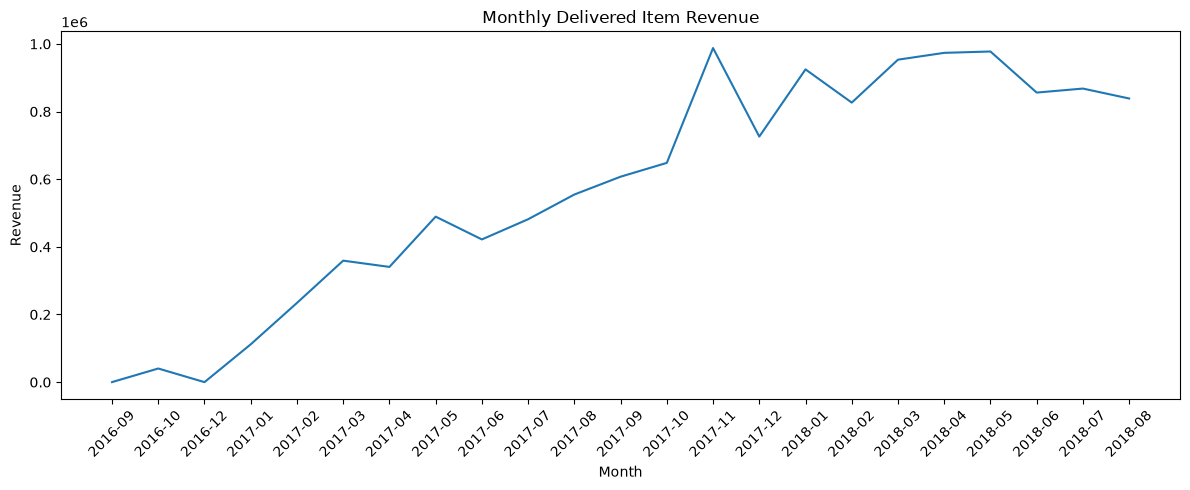

In [163]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["order_month"].astype(str),
    monthly_revenue["item_revenue"]
)

plt.title("Monthly Delivered Item Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [164]:
monthly_orders = (
    sales[sales["order_status"] == "delivered"]
    .groupby("order_month")["order_id"]
    .nunique()
    .reset_index()
)

In [165]:
monthly_orders.head(10)

,order_month,order_id
0,2016-09,1
1,2016-10,265
2,2016-12,1
3,2017-01,750
4,2017-02,1653
5,2017-03,2546
6,2017-04,2303
7,2017-05,3546
8,2017-06,3135
9,2017-07,3872


In [166]:
monthly_orders.tail()

,order_month,order_id
18,2018-04,6798
19,2018-05,6749
20,2018-06,6099
21,2018-07,6159
22,2018-08,6351


In [167]:
monthly_orders.shape

(23, 2)

In [168]:
monthly_analysis = pd.merge(
    monthly_revenue,
    monthly_orders,
    on="order_month",
    how="inner"
)

In [169]:
monthly_analysis.head()

,order_month,item_revenue,order_id
0,2016-09,134.97,1
1,2016-10,40325.11,265
2,2016-12,10.90,1
3,2017-01,111798.36,750
4,2017-02,234223.40,1653


In [170]:
monthly_analysis.shape

(23, 3)

In [171]:
monthly_analysis["aov"] = (
    monthly_analysis["item_revenue"] /
    monthly_analysis["order_id"]
)

In [172]:
monthly_analysis.head()

,order_month,item_revenue,order_id,aov
0,2016-09,134.97,1,134.970000
1,2016-10,40325.11,265,152.170226
2,2016-12,10.90,1,10.900000
3,2017-01,111798.36,750,149.064480
4,2017-02,234223.40,1653,141.695947


In [173]:
monthly_analysis.tail(10)

,order_month,item_revenue,order_id,aov
13,2017-11,987765.37,7289,135.514525
14,2017-12,726033.19,5513,131.694756
15,2018-01,924645.00,7069,130.802801
16,2018-02,826437.13,6555,126.077365
17,2018-03,953356.25,7003,136.135406
18,2018-04,973534.09,6798,143.208898
19,2018-05,977544.69,6749,144.842894
20,2018-06,856077.86,6099,140.363643
21,2018-07,867953.46,6159,140.924413
22,2018-08,838576.64,6351,132.038520


In [174]:
monthly_analysis["aov"].describe()

count     23.000000
mean     133.034398
std       27.595875
min       10.900000
25%      132.165182
50%      137.997250
75%      143.985830
max      152.170226
Name: aov, dtype: float64

In [175]:
monthly_analysis["aov"].mean()

np.float64(133.0343976534036)

In [176]:
overall_aov = (
    monthly_analysis["item_revenue"].sum() /
    monthly_analysis["order_id"].sum()
)

overall_aov

np.float64(137.0415857501192)

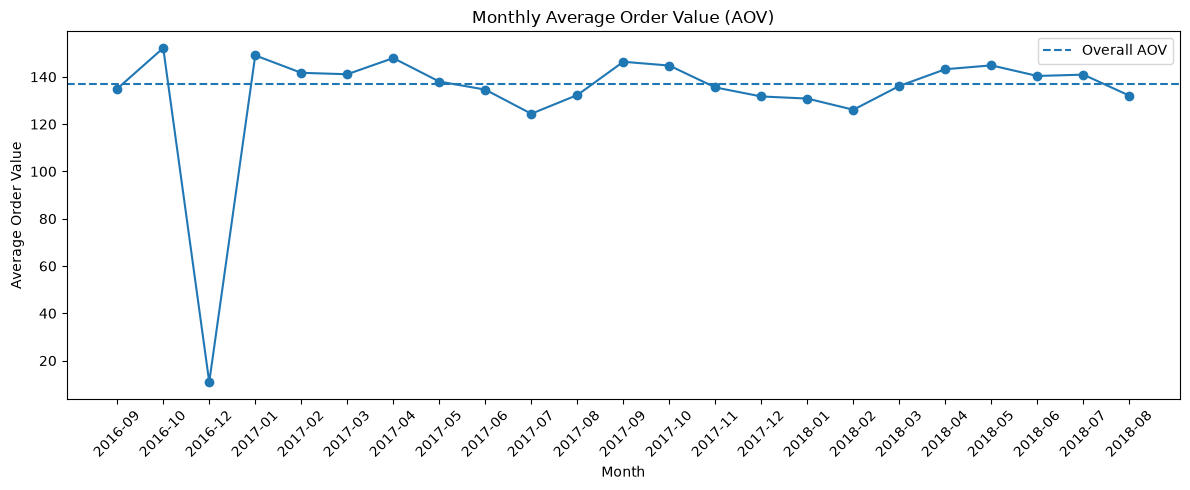

In [177]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_analysis["order_month"].astype(str),
    monthly_analysis["aov"],
    marker="o"
)

plt.axhline(
    overall_aov,
    linestyle="--",
    label="Overall AOV"
)

plt.title("Monthly Average Order Value (AOV)")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [178]:
customers = pd.read_csv(
    "../data/olist_customers_dataset.csv"
)

In [179]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [180]:
customers.shape

(99441, 5)

In [181]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [182]:
customers["customer_unique_id"].nunique()

96096

In [183]:
customer_orders = pd.merge(
    orders_clean,
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

In [184]:
customer_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_month,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,72632f0f9dd73dfee390c9b22eb56dd6


In [185]:
customer_orders.shape

(99441, 10)

In [186]:
customer_orders["customer_unique_id"].isnull().sum()

np.int64(0)

In [187]:
delivered_customer_orders = customer_orders[
    customer_orders["order_status"] == "delivered"
]

In [188]:
customer_frequency = (
    delivered_customer_orders
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index()
)

In [189]:
customer_frequency.head(10)

,customer_unique_id,order_id
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1
5,0004bd2a26a76fe21f786e4fbd80607f,1
6,00050ab1314c0e55a6ca13cf7181fecf,1
7,00053a61a98854899e70ed204dd4bafe,1
8,0005e1862207bf6ccc02e4228effd9a0,1
9,0005ef4cd20d2893f0d9fbd94d3c0d97,1


In [190]:
customer_frequency["order_id"].value_counts()

order_id
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [191]:
one_time_customers = (
    customer_frequency["order_id"] == 1
).sum()

repeat_customers = (
    customer_frequency["order_id"] > 1
).sum()

total_customers = len(customer_frequency)

repeat_purchase_rate = (
    repeat_customers / total_customers
) * 100

print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)
print("Total customers:", total_customers)
print("Repeat purchase rate:", round(repeat_purchase_rate, 2), "%")

One-time customers: 90557
Repeat customers: 2801
Total customers: 93358
Repeat purchase rate: 3.0 %


In [192]:
average_orders_per_customer = (
    customer_frequency["order_id"].mean()
)

average_orders_per_customer

np.float64(1.0334197390689603)

<Axes: title={'center': 'Distribution of Orders per Customer'}, xlabel='Number of Orders', ylabel='Number of Customers'>

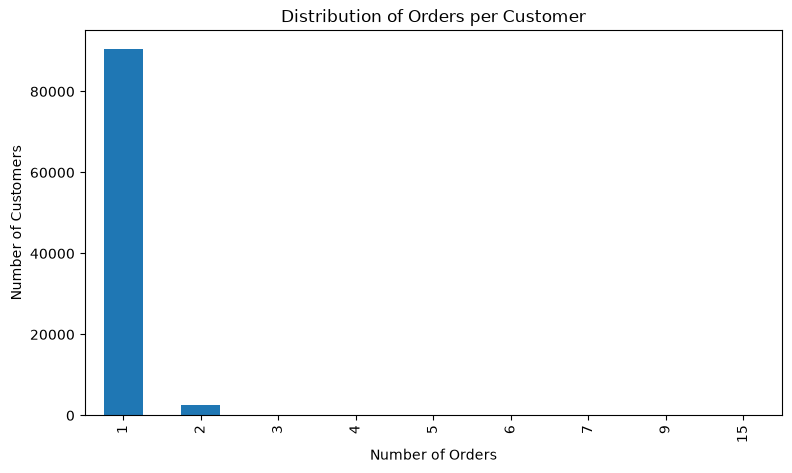

In [193]:
customer_frequency["order_id"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Orders per Customer",
    xlabel="Number of Orders",
    ylabel="Number of Customers"
)

<Axes: title={'center': 'Distribution of Orders per Customer (Log Scale)'}, xlabel='Number of Orders', ylabel='Number of Customers (Log Scale)'>

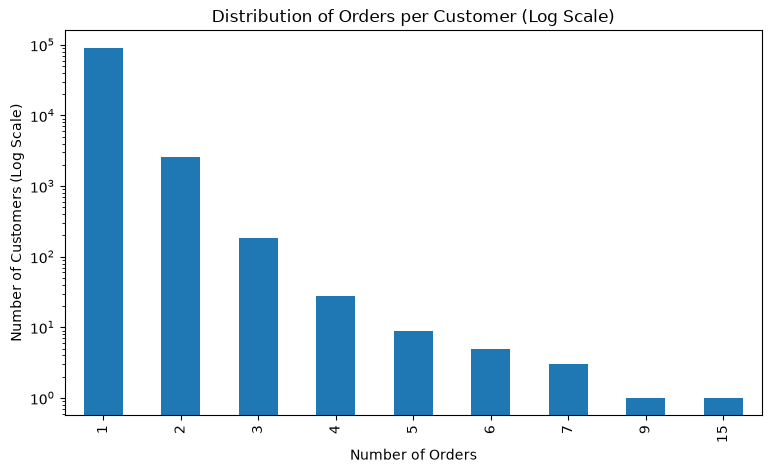

In [194]:
customer_frequency["order_id"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(9, 5),
    logy=True,
    title="Distribution of Orders per Customer (Log Scale)",
    xlabel="Number of Orders",
    ylabel="Number of Customers (Log Scale)"
)

In [195]:
customer_by_state = (
    customers
    .groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

customer_by_state.head(10)

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
Name: customer_unique_id, dtype: int64

<Axes: title={'center': 'Top 10 States by Number of Customers'}, xlabel='State', ylabel='Number of Unique Customers'>

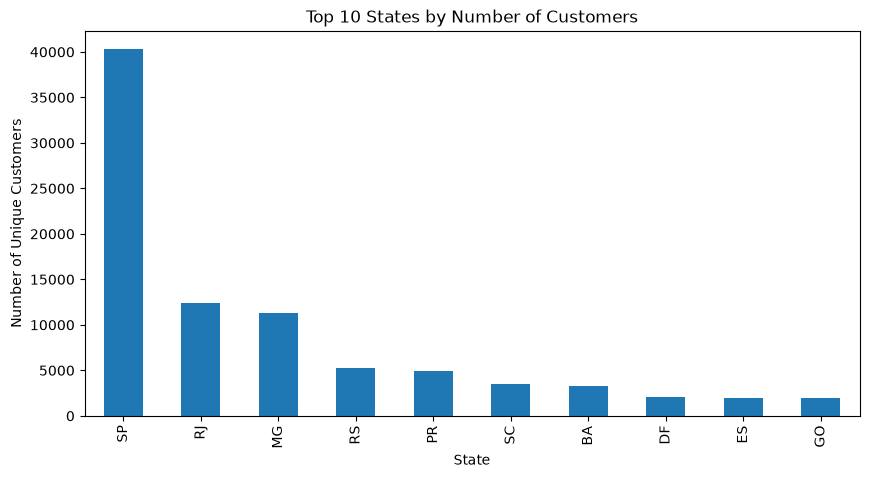

In [196]:
customer_by_state.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 States by Number of Customers",
    xlabel="State",
    ylabel="Number of Unique Customers"
)

In [197]:
state_percentage = (
    customer_by_state / customer_by_state.sum()
) * 100

state_percentage.head(10).round(2)

customer_state
SP    41.92
RJ    12.88
MG    11.71
RS     5.49
PR     5.08
SC     3.68
BA     3.41
DF     2.16
ES     2.04
GO     2.03
Name: customer_unique_id, dtype: float64

In [198]:
customer_by_state / customer_by_state.sum() * 100

customer_state
SP    41.921861
RJ    12.881751
MG    11.711534
RS     5.489099
PR     5.078223
SC     3.676042
BA     3.408713
DF     2.158401
ES     2.042939
GO     2.030457
PE     1.673671
CE     1.365773
PA     0.987143
MT     0.911209
MA     0.755180
MS     0.721894
PB     0.539860
PI     0.501373
RN     0.493052
AL     0.417117
SE     0.355746
TO     0.283973
RO     0.249646
AM     0.148748
AC     0.080095
AP     0.069693
RR     0.046809
Name: customer_unique_id, dtype: float64

In [199]:
customer_by_city = (
    customers
    .groupby(["customer_city", "customer_state"])["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

customer_by_city.head(15)

customer_city          customer_state
sao paulo              SP                14984
rio de janeiro         RJ                 6620
belo horizonte         MG                 2672
brasilia               DF                 2069
curitiba               PR                 1465
campinas               SP                 1398
porto alegre           RS                 1326
salvador               BA                 1209
guarulhos              SP                 1153
sao bernardo do campo  SP                  908
niteroi                RJ                  811
santo andre            SP                  768
osasco                 SP                  717
santos                 SP                  692
goiania                GO                  671
Name: customer_unique_id, dtype: int64

<Axes: title={'center': 'Top 10 Cities by Number of Customers'}, xlabel='Number of Unique Customers', ylabel='City, State'>

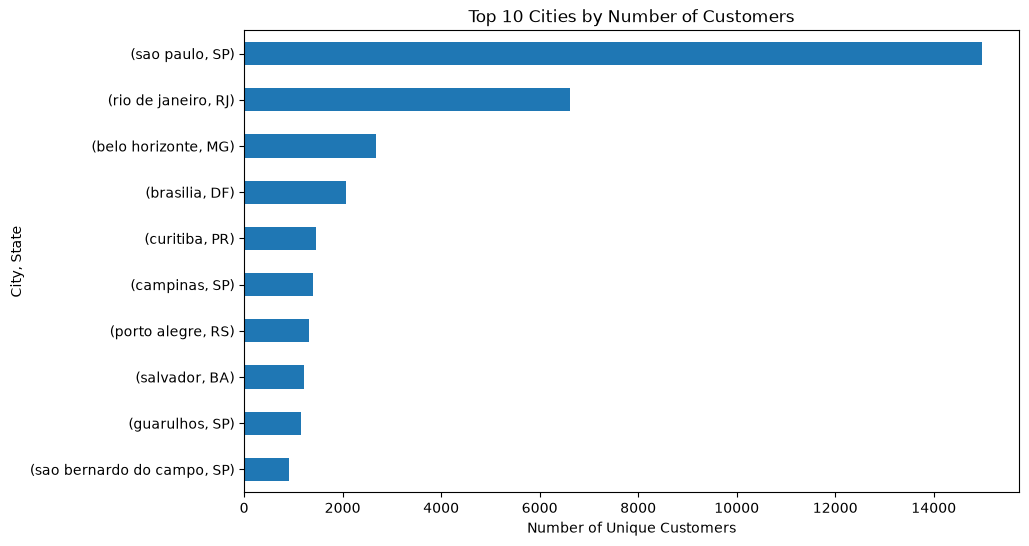

In [200]:
customer_by_city.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Cities by Number of Customers",
    xlabel="Number of Unique Customers",
    ylabel="City, State"
)

### Geographic Analysis Findings

- São Paulo is the largest customer market, accounting for 41.92% of all unique customers at the state level.
- Rio de Janeiro and Minas Gerais are the second and third largest states.
- São Paulo city has 14,984 unique customers, significantly higher than other cities.
- Several cities within São Paulo state appear in the top 15, indicating strong regional customer concentration.

**Business implication:**
Olist could prioritize marketing campaigns and operational planning in high-customer-density regions while exploring growth opportunities in less represented states.

In [201]:
products = pd.read_csv(
    "../data/olist_products_dataset.csv"
)

products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [202]:
products.shape

(32951, 9)

In [203]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [204]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [205]:
product_sales = pd.merge(
    sales,
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [206]:
product_sales.shape

(112650, 17)

In [207]:
product_sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_month,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,item_revenue,product_category_name
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,29.99,utilidades_domesticas
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018-07,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,118.70,perfumaria
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018-08,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,159.90,automotivo
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,45.00,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018-02,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,19.90,papelaria


In [208]:
product_sales["product_category_name"].isnull().sum()

np.int64(1603)

In [209]:
import pandas as pd
import numpy as np

In [210]:
product_sales = pd.merge(
    sales,
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [211]:
%whos

Variable                      Type         Data/Info
----------------------------------------------------
average_orders_per_customer   float64      1.0334197390689603
category_orders               Series       Shape: (74,)
col                           str          order_estimated_delivery_date
customer_by_city              Series       Shape: (4310,)
customer_by_state             Series       Shape: (27,)
customer_frequency            DataFrame    Shape: (93358, 2)
customer_orders               DataFrame    Shape: (99441, 10)
customers                     DataFrame    Shape: (99441, 5)
date_columns                  list         n=4
delivered_customer_orders     DataFrame    Shape: (96478, 10)
delivered_revenue             float64      13221498.110000001
monthly_analysis              DataFrame    Shape: (23, 4)
monthly_orders                DataFrame    Shape: (23, 2)
monthly_revenue               DataFrame    Shape: (23, 2)
np                            module       <module 'numpy' f

In [212]:
orders = pd.read_csv("../data/olist_orders_dataset.csv")
order_items = pd.read_csv("../data/olist_order_items_dataset.csv")
products = pd.read_csv("../data/olist_products_dataset.csv")

In [213]:
product_sales = pd.merge(
    sales,
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [214]:
orders_clean = orders.copy()

orders_clean = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].notnull())
]

In [215]:
order_items_clean = order_items.copy()

In [216]:
sales = pd.merge(
    orders_clean,
    order_items_clean,
    on="order_id",
    how="inner"
)

In [217]:
sales.shape

(110189, 14)

In [218]:
sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [219]:
product_sales = pd.merge(
    sales,
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [220]:
product_sales.shape

(110189, 15)

In [221]:
product_sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,papelaria


In [222]:
product_sales.shape

(110189, 15)

In [223]:
product_sales["product_category_name"].isnull().sum()

np.int64(1537)

In [224]:
product_sales["product_category_name"] = (
    product_sales["product_category_name"].fillna("unknown")
)

In [225]:
product_sales["product_category_name"].isnull().sum()

np.int64(0)

In [226]:
category_orders = (
    product_sales.groupby("product_category_name")
    ["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

category_orders.head(10)

product_category_name
cama_mesa_banho           9272
beleza_saude              8647
esporte_lazer             7529
informatica_acessorios    6529
moveis_decoracao          6307
utilidades_domesticas     5743
relogios_presentes        5493
telefonia                 4093
automotivo                3809
brinquedos                3803
Name: order_id, dtype: int64

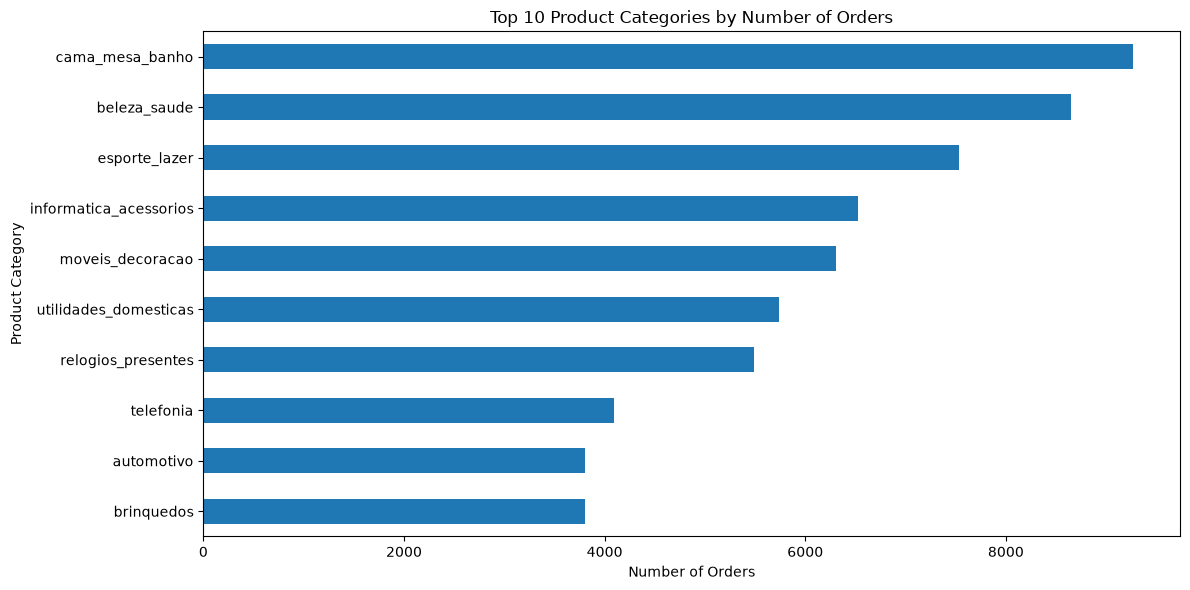

In [227]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

category_orders.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Product Categories by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [228]:
category_revenue = (
    product_sales.groupby("product_category_name")
    ["item_revenue"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue.head(10)

KeyError: 'Column not found: item_revenue'

In [ ]:
product_sales.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value',
 'product_category_name']

In [230]:
product_sales[["price", "freight_value"]].head()

,price,freight_value
0,29.99,8.72
1,118.70,22.76
2,159.90,19.22
3,45.00,27.20
4,19.90,8.72


In [231]:
product_sales["item_revenue"] = product_sales["price"]

In [232]:
category_revenue = (
    product_sales.groupby("product_category_name")
    ["item_revenue"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue.head(10)

product_category_name
beleza_saude              1233131.72
relogios_presentes        1165898.98
cama_mesa_banho           1023434.76
esporte_lazer              954673.55
informatica_acessorios     888613.62
moveis_decoracao           711927.69
utilidades_domesticas      615628.69
cool_stuff                 610204.10
automotivo                 578849.35
brinquedos                 471097.49
Name: item_revenue, dtype: float64

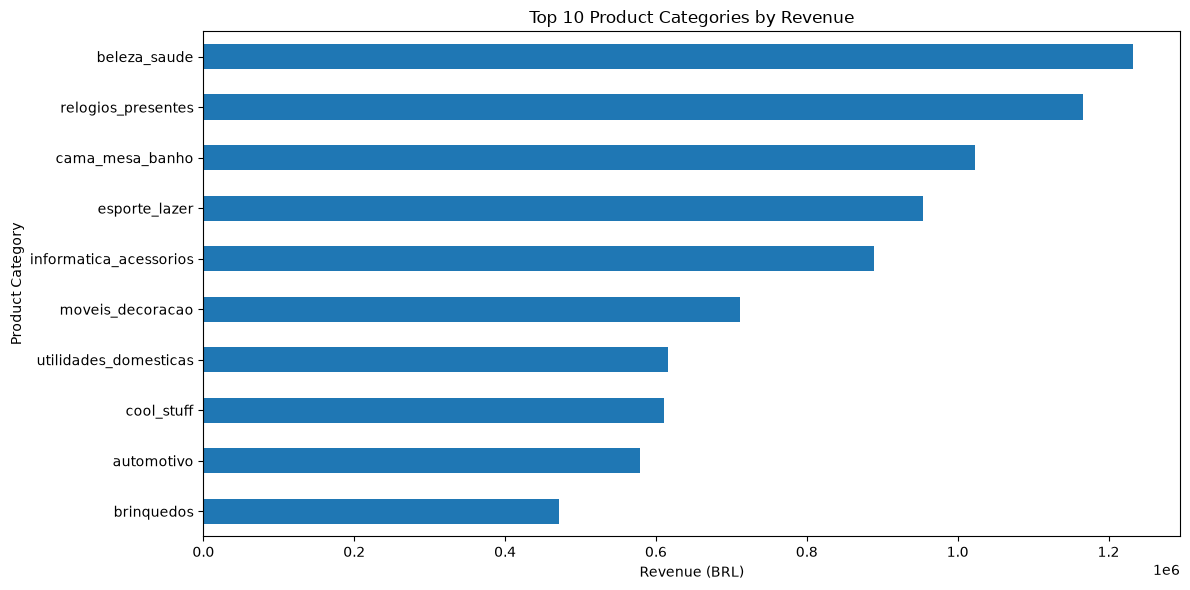

In [233]:
plt.figure(figsize=(12, 6))

category_revenue.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [234]:
category_comparison = pd.DataFrame({
    "total_orders": category_orders,
    "total_revenue": category_revenue
})

category_comparison.head(10)

,total_orders,total_revenue
product_category_name,,
agro_industria_e_comercio,177,70566.10
alimentos,441,28731.15
alimentos_bebidas,221,14942.88
artes,195,23657.30
artes_e_artesanato,23,1814.01
artigos_de_festas,38,4465.19
artigos_de_natal,125,8737.84
audio,348,50570.60
automotivo,3809,578849.35


In [235]:
category_comparison["revenue_per_order"] = (
    category_comparison["total_revenue"] /
    category_comparison["total_orders"]
)

In [236]:
category_comparison = category_comparison.sort_values(
    by="total_revenue",
    ascending=False
)

category_comparison.head(10).round(2)

,total_orders,total_revenue,revenue_per_order
product_category_name,,,
beleza_saude,8647,1233131.72,142.61
relogios_presentes,5493,1165898.98,212.25
cama_mesa_banho,9272,1023434.76,110.38
esporte_lazer,7529,954673.55,126.80
informatica_acessorios,6529,888613.62,136.10
moveis_decoracao,6307,711927.69,112.88
utilidades_domesticas,5743,615628.69,107.20
cool_stuff,3559,610204.10,171.45
automotivo,3809,578849.35,151.97


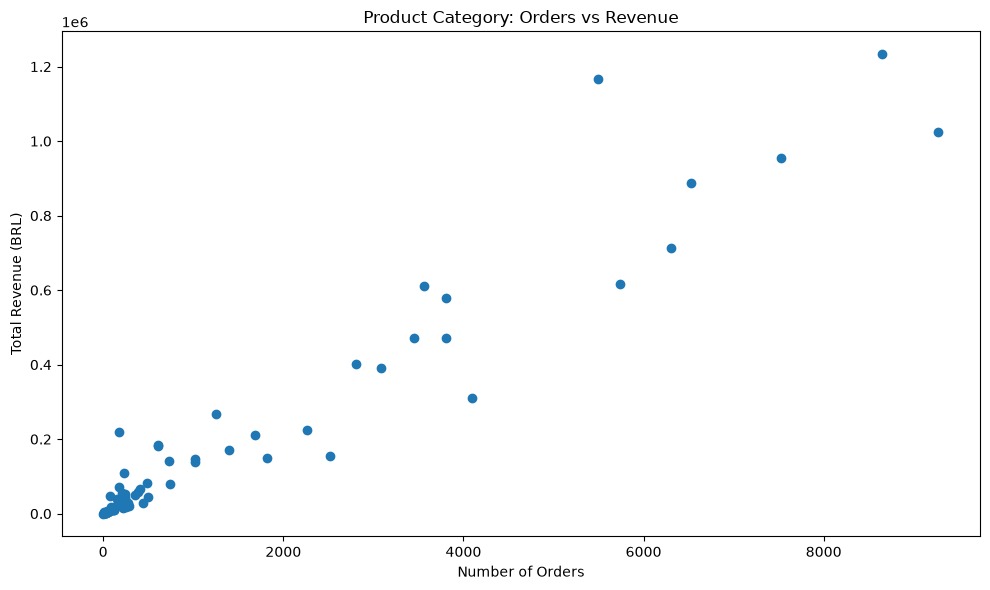

In [237]:
plt.figure(figsize=(10, 6))

plt.scatter(
    category_comparison["total_orders"],
    category_comparison["total_revenue"]
)

plt.title("Product Category: Orders vs Revenue")
plt.xlabel("Number of Orders")
plt.ylabel("Total Revenue (BRL)")

plt.tight_layout()
plt.show()

In [238]:
correlation = category_comparison[
    ["total_orders", "total_revenue"]
].corr()

correlation

,total_orders,total_revenue
total_orders,1.000000,0.960038
total_revenue,0.960038,1.000000


### Product Category Analysis - Key Findings

- cama_mesa_banho has the highest order volume.
- beleza_saude generates the highest total revenue.
- relogios_presentes has the highest revenue per order.
- Order volume and revenue have a strong positive correlation (0.96).

Business Insight:
Product categories with higher order volumes generally generate higher revenue. 
However, differences in revenue per order also influence overall category performance.

In [240]:
payments = pd.read_csv(
    "../data/olist_order_payments_dataset.csv"
)

In [241]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [242]:
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [243]:
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

### Payment Method Analysis

Analyze the distribution of payment methods 
and identify the most commonly used payment types.

In [244]:
payment_methods = (
    payments["payment_type"]
    .value_counts()
)

payment_methods

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [245]:
payment_percentage = (
    payments["payment_type"]
    .value_counts(normalize=True) * 100
)

payment_percentage.round(2)

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64

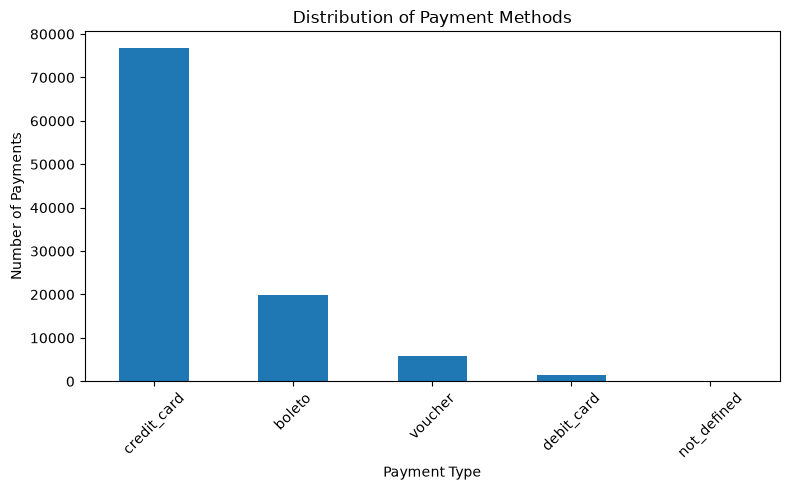

In [246]:
import matplotlib.pyplot as plt

payment_methods.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Payment Methods")
plt.xlabel("Payment Type")
plt.ylabel("Number of Payments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Key Findings

- Credit card dominates payment methods, accounting for approximately 73.92% of payment records.
- Boleto is the second most popular payment method at approximately 19.04%.
- Voucher and debit card payments represent relatively small proportions.
- The business relies heavily on credit card payments.

**Business Implication:**
The company should maintain a reliable credit card payment infrastructure while exploring opportunities to improve adoption of alternative payment methods.

In [247]:
installment_distribution = (
    payments["payment_installments"]
    .value_counts()
    .sort_index()
)

installment_distribution

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

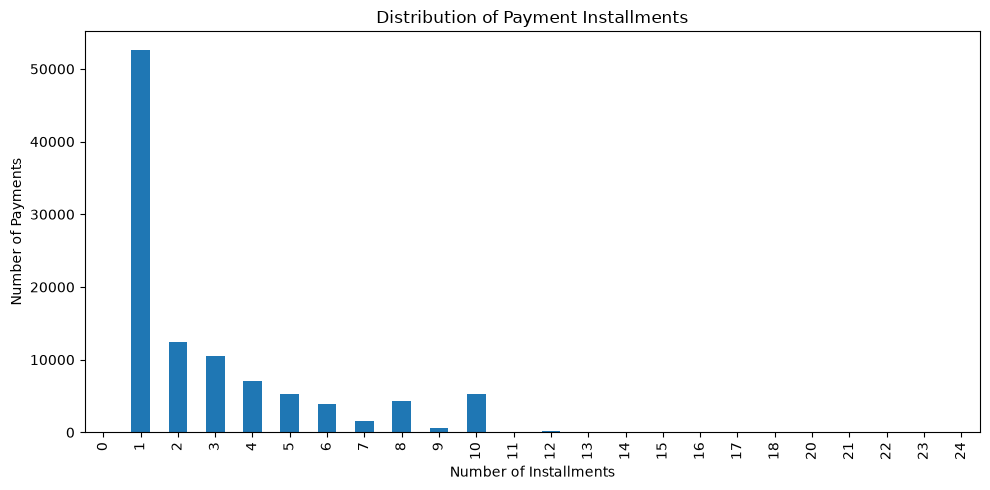

In [248]:
installment_distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribution of Payment Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Payments")
plt.tight_layout()
plt.show()

In [249]:
payments["payment_installments"].describe()

count    103886.000000
mean          2.853349
std           2.687051
min           0.000000
25%           1.000000
50%           1.000000
75%           4.000000
max          24.000000
Name: payment_installments, dtype: float64

In [250]:
payments["payment_installments"].value_counts().sort_index()

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [251]:
installment_by_method = (
    payments.groupby("payment_type")
    ["payment_installments"]
    .agg(["mean", "median", "max", "count"])
    .round(2)
)

installment_by_method

,mean,median,max,count
payment_type,,,,
boleto,1.00,1.0,1,19784
credit_card,3.51,3.0,24,76795
debit_card,1.00,1.0,1,1529
not_defined,1.00,1.0,1,3
voucher,1.00,1.0,1,5775


#### Installment Analysis - Key Findings

- Credit card payments have an average of 3.51 installments.
- The median installment for credit card payments is 3.
- Credit card payments can reach up to 24 installments.
- Other payment methods consistently use 1 installment.

**Business Implication:**

Credit card installment options provide customers with greater payment flexibility. 
The business could further investigate whether installment usage is associated 
with higher transaction values.

In [252]:
payment_value_analysis = (
    payments.groupby("payment_type")["payment_value"]
    .agg(["count", "sum", "mean", "median"])
    .round(2)
    .sort_values("sum", ascending=False)
)

payment_value_analysis

,count,sum,mean,median
payment_type,,,,
credit_card,76795,12542084.19,163.32,106.87
boleto,19784,2869361.27,145.03,93.89
voucher,5775,379436.87,65.70,39.28
debit_card,1529,217989.79,142.57,89.30
not_defined,3,0.00,0.00,0.00


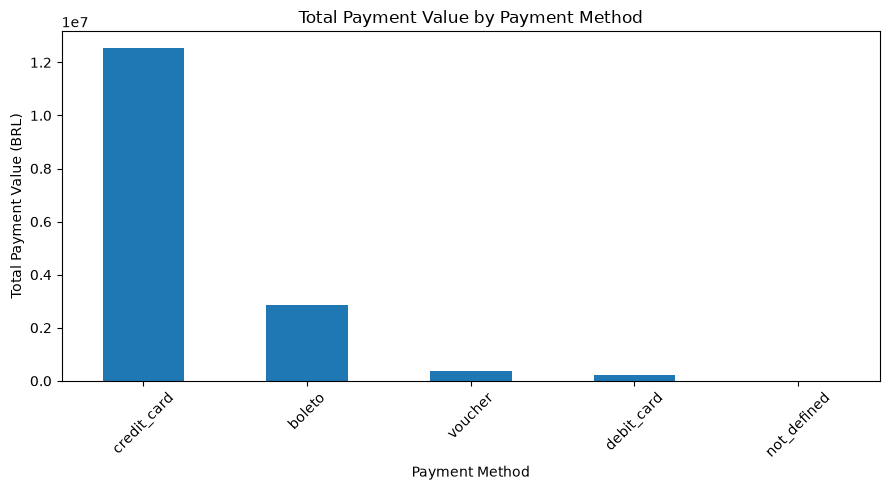

In [253]:
payment_value_analysis["sum"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Value (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

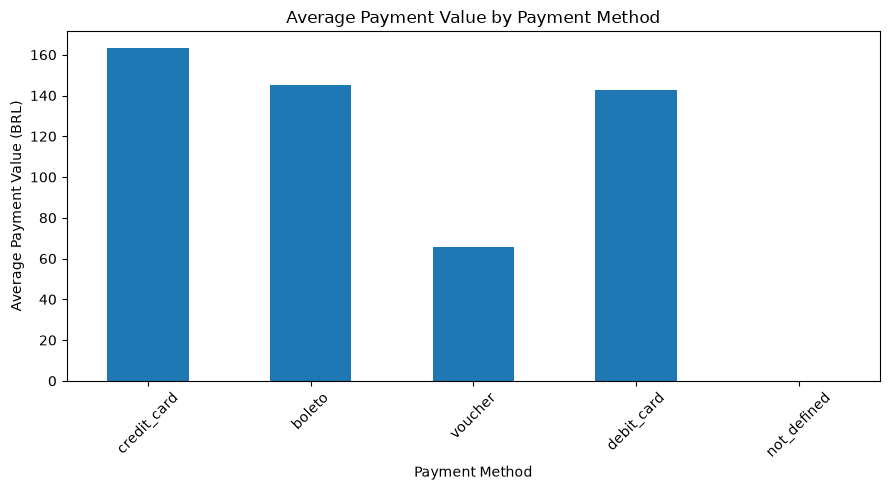

In [254]:
payment_value_analysis["mean"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Payment Value (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Payment Value Analysis - Key Findings

- Credit card generates the highest total payment value 
  at approximately BRL 12.54 million.
- Debit card has an average payment value comparable 
  to boleto despite having significantly fewer transactions.
- Voucher has the lowest average payment value at BRL 65.70.
- Credit card has a higher mean than median, suggesting 
  the presence of higher-value payment records.

**Business Implication:**

Credit card is the primary payment channel in terms of 
both transaction volume and total payment value. 
The company should maintain this payment channel while 
exploring opportunities to improve alternative payment methods.

In [255]:
installment_value = (
    payments.groupby("payment_installments")["payment_value"]
    .agg(["count", "mean", "median", "sum"])
    .round(2)
)

installment_value.head(15)

,count,mean,median,sum
payment_installments,,,,
0,2,94.32,94.32,188.63
1,52546,112.42,73.34,5907233.36
2,12413,127.23,109.42,1579283.03
3,10461,142.54,110.42,1491103.80
4,7098,163.98,117.18,1163907.61
5,5239,183.47,125.97,961174.30
6,3920,209.85,138.55,822611.81
7,1626,187.67,140.07,305157.39
8,4268,307.74,212.70,1313423.34


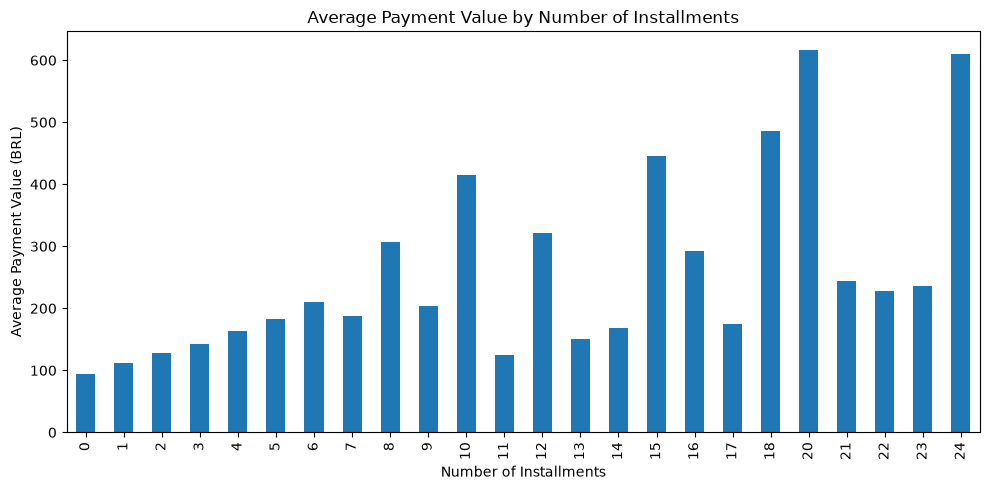

In [256]:
installment_value["mean"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Payment Value by Number of Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Average Payment Value (BRL)")
plt.tight_layout()
plt.show()

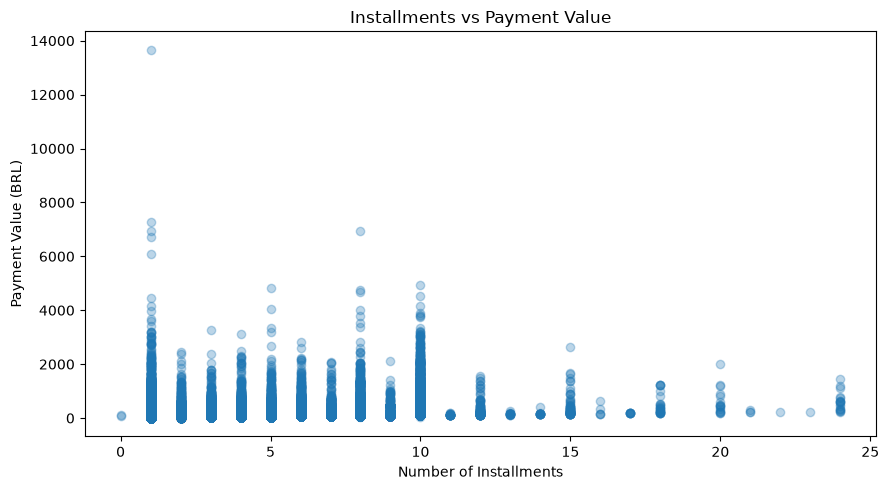

In [257]:
plt.figure(figsize=(9, 5))

plt.scatter(
    payments["payment_installments"],
    payments["payment_value"],
    alpha=0.3
)

plt.title("Installments vs Payment Value")
plt.xlabel("Number of Installments")
plt.ylabel("Payment Value (BRL)")
plt.tight_layout()
plt.show()

### Credit Card Installment Behaviour

Analyze the relationship between the number of 
credit card installments and payment value.

This analysis focuses only on credit card payments 
to understand installment behaviour more accurately.

In [258]:
credit_card_payments = payments[
    payments["payment_type"] == "credit_card"
]

credit_card_payments.shape

(76795, 5)

In [259]:
credit_installment_analysis = (
    credit_card_payments
    .groupby("payment_installments")["payment_value"]
    .agg(["count", "mean", "median", "sum"])
    .round(2)
)

credit_installment_analysis

,count,mean,median,sum
payment_installments,,,,
0,2,94.32,94.32,188.63
1,25455,95.87,67.87,2440445.43
2,12413,127.23,109.42,1579283.03
3,10461,142.54,110.42,1491103.80
4,7098,163.98,117.18,1163907.61
5,5239,183.47,125.97,961174.30
6,3920,209.85,138.55,822611.81
7,1626,187.67,140.07,305157.39
8,4268,307.74,212.70,1313423.34


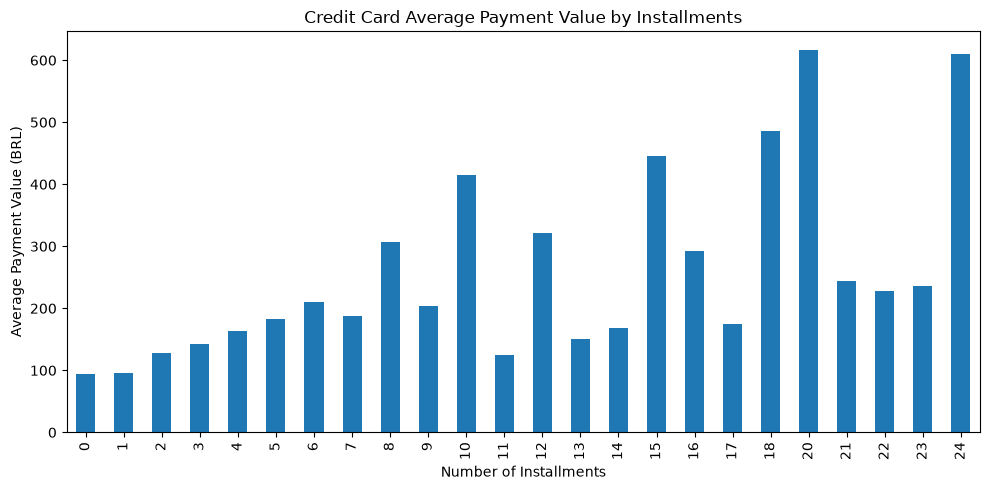

In [260]:
credit_installment_analysis["mean"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Credit Card Average Payment Value by Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Average Payment Value (BRL)")
plt.tight_layout()
plt.show()

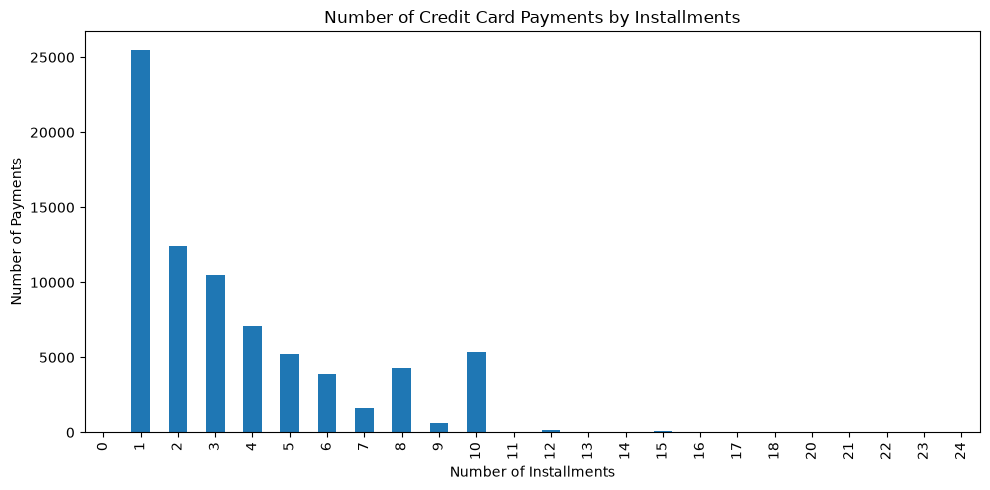

In [261]:
credit_installment_analysis["count"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Number of Credit Card Payments by Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Payments")
plt.tight_layout()
plt.show()

#### Credit Card Installment Analysis - Key Findings

- Average payment value generally increases with the number of installments.
- Higher installment options are associated with higher average payment values.
- The relationship is not perfectly linear.
- Higher installment groups have fewer observations, requiring cautious interpretation.

**Business Implication:**

Offering flexible installment options may support customers making higher-value purchases. 
However, further analysis is needed to establish the relationship more reliably.

#### Credit Card Installment Analysis - Key Findings

- One installment is the most popular option among credit card payments.
- Payment frequency generally decreases as the number of installments increases.
- Average payment value generally increases with the number of installments.
- Installment options of 8 and 10 months remain relatively popular.
- Very long installment plans are rarely used.

**Business Implication:**

Most customers prefer shorter payment plans, while longer installment options may support higher-value purchases. The business should maintain flexible installment options while monitoring customer preferences.

# 7. Final EDA Summary & Business Recommendations

This section summarizes the key findings from the exploratory 
data analysis and translates them into actionable business insights.

The analysis covers:
1. Sales Performance
2. Customer Behaviour
3. Geographic Distribution
4. Product Category Performance
5. Payment Behaviour

### 7.1 Sales Performance

**Key Findings:**
- Monthly revenue increased significantly from early 2017 and remained relatively stable at a higher level throughout 2018.
- Monthly order volume followed a similar upward trend, indicating business growth.
- Overall Average Order Value (AOV) was approximately R$137.04.
- Monthly AOV remained relatively stable, suggesting consistent customer spending per order.

**Business Implications:**

The business demonstrates positive growth in both revenue and order volume. The company should maintain its current sales strategy while exploring opportunities to increase customer spending through product bundles, promotions, and targeted campaigns.


### 7.2 Customer Behaviour

**Key Findings:**
- The dataset contains 96,096 unique customers.
- Approximately 90,557 customers made only one purchase.
- Only 2,801 customers made repeat purchases.
- The repeat purchase rate is approximately 3.0%.
- Customer distribution is highly concentrated in São Paulo (SP), which accounts for approximately 41.92% of customers.

**Business Implications:**

The low repeat purchase rate indicates an opportunity to improve customer retention. The business should consider loyalty programmes, personalised promotions, and post-purchase engagement campaigns to encourage customers to make additional purchases.

### 7.3 Geographic Distribution

**Key Findings:**
- São Paulo (SP) has the largest customer base, representing approximately 41.92% of all customers.
- Rio de Janeiro (RJ) and Minas Gerais (MG) are the second and third largest customer markets.
- São Paulo city has the highest number of customers, followed by Rio de Janeiro and Belo Horizonte.
- Customer distribution is concentrated in Brazil's southeastern states.

**Business Implications:**

The company should maintain strong logistics and marketing operations in major customer markets, particularly São Paulo, Rio de Janeiro, and Minas Gerais. There may also be opportunities to expand into states with lower customer representation through targeted marketing and improved delivery coverage.

### 7.4 Product Category Performance

**Key Findings:**
- Beauty and Health (beleza_saude) generated the highest total revenue of approximately R$1.23 million.
- Watches and Gifts (relogios_presentes) generated approximately R$1.17 million.
- Bed, Bath and Table (cama_mesa_banho) recorded the highest order volume, with 9,272 orders.
- Watches and Gifts achieved the highest revenue per order at approximately R$212.25.
- Product categories show a positive relationship between order volume and total revenue, with a correlation of approximately 0.96.

**Business Implications:**

The business should prioritise high-revenue categories while maintaining sufficient inventory for popular products. Categories with high revenue per order may offer opportunities for premium promotions, product bundles, and targeted marketing campaigns.

### 7.5 Payment Behaviour

**Key Findings:**
- Credit cards are the most frequently used payment method, accounting for 76,795 payments.
- Boleto is the second most popular payment method, with 19,784 payments.
- Most customers prefer one-installment payments, with 52,546 payments.
- Payment frequency generally decreases as the number of installments increases.
- Credit card payments have the highest total payment value, approximately R$12.54 million.
- Longer installment plans generally show higher average payment values, although some installment groups have relatively few transactions.

**Business Implications:**

The business should continue supporting credit card and boleto payments as its primary payment methods. Flexible installment options should also be maintained to accommodate different customer spending preferences. Longer installment plans may help support higher-value purchases, but their performance should be monitored due to lower transaction volumes.

### 7.6 Overall Business Recommendations

Based on the exploratory data analysis, the following recommendations are proposed:

1. **Improve Customer Retention**
   - Introduce loyalty programmes and personalised promotions.
   - Encourage repeat purchases through post-purchase engagement.

2. **Strengthen Sales Performance**
   - Maintain strategies that support consistent revenue and order growth.
   - Use product bundles and promotional campaigns to increase average order value.

3. **Optimise Geographic Marketing**
   - Focus marketing and logistics resources on high-customer-density states.
   - Explore expansion opportunities in less-represented regions.

4. **Prioritise High-Performing Product Categories**
   - Maintain sufficient inventory for popular and high-revenue categories.
   - Develop targeted campaigns for categories with high revenue per order.

5. **Maintain Flexible Payment Options**
   - Continue supporting popular payment methods.
   - Monitor installment preferences and payment values to optimise payment offerings.

### 7.7 EDA Conclusion

The exploratory data analysis provides an overview of Olist's sales performance, customer behaviour, geographic distribution, product category performance, and payment patterns.

The findings indicate that the business experienced revenue and order growth, while customer activity was concentrated in specific geographic markets and repeat purchasing remained relatively low.

Overall, the analysis highlights opportunities to improve customer retention, optimise product strategies, strengthen geographic marketing, and maintain flexible payment options.

These findings provide a foundation for further data analysis and business intelligence dashboard development.
